In [14]:
import numpy as np
import struct
import matplotlib.pyplot as plt

In [15]:
with open('prof.bin', 'rb') as f:
    data = f.read()
threads, = struct.unpack('q', data[:8])
data = np.frombuffer(data[8:], dtype=np.uint64).reshape(threads, -1, 6)

In [16]:
cost = np.diff(data, axis=-1)
cost.shape

(2, 1000000, 5)

In [17]:
avg_cost = cost.mean(axis=1)

In [18]:
names = [
    '1. barrier',
    '2. pull',
    '3. step',
    '4. barrier',
    '5. push',
]

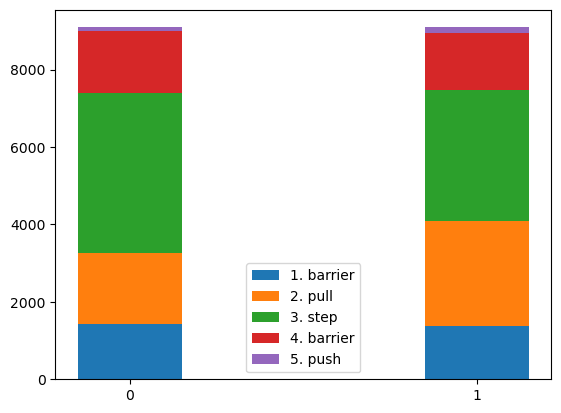

In [19]:
x = np.arange(cost.shape[0])
for i in range(5):
    plt.bar(x, avg_cost[:, i], bottom=np.sum(avg_cost[:, :i], axis=-1), width=0.3, label=names[i])
plt.legend()
plt.xticks(x, x)
plt.show()

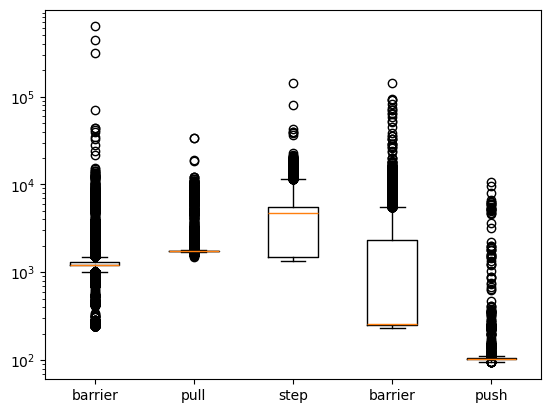

In [20]:
plt.boxplot(cost[0, 600000:], tick_labels=['barrier', 'pull', 'step', 'barrier', 'push'])
plt.yscale('log')